# Ames Housing — Exploratory Data Analysis (EDA)

**Purpose:** Explore the same Ames Housing training data used for the final house-price model. The target is `SalePrice` in US dollars. This notebook replaces the earlier Indian-housing EDA as the evidence base for the Ames model; the Indian dataset and its results must remain clearly labelled as a separate prototype.

**Important:** This is an exploratory notebook. It flags potential data-quality and outlier issues but does not delete rows or make preprocessing decisions automatically. Those decisions must be justified and implemented inside the model's training pipeline.

**Expected input:** `data/raw/ames_housing/train.csv` relative to the repository root. The raw file is ignored by Git; each teammate should obtain the same permitted source version.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root regardless of whether Jupyter was launched from
# the repository root or from notebooks/ames_housing.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next(
    (p for p in _candidates if (p / "data" / "raw" / "ames_housing" / "train.csv").exists()),
    None,
)
if PROJECT_ROOT is None:
    # Also support an unpopulated clean checkout: locate the .git directory/file.
    PROJECT_ROOT = next(
        (p for p in _candidates if (p / ".git").exists()),
        _here,
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ames_housing" / "train.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "ames_eda"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())
print("Figure output directory:", FIGURE_DIR)


Project root: /mnt/d/IDC409_Group18_Final
Dataset path: /mnt/d/IDC409_Group18_Final/data/raw/ames_housing/train.csv
Dataset exists: True
Figure output directory: /mnt/d/IDC409_Group18_Final/reports/figures/ames_eda


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Ames train.csv was not found at {DATA_PATH}. "
        "Place the approved labelled training CSV at data/raw/ames_housing/train.csv."
    )

df = pd.read_csv(DATA_PATH)
TARGET = "SalePrice"

if TARGET not in df.columns:
    raise ValueError(f"Required target column {TARGET!r} is missing. Found columns: {list(df.columns)}")

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print(f"Target: {TARGET}")
print("Target missing values:", int(df[TARGET].isna().sum()))
display(df.head())


Rows: 1,460
Columns: 81
Target: SalePrice
Target missing values: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Schema and data integrity

Review the dimensions, column types, duplicate records, duplicate identifiers (if `Id` exists), and whether the target has missing or invalid values. These checks describe the data; they do not silently modify it.


In [3]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "distinct_values": df.nunique(dropna=True),
}).sort_values("missing_percent", ascending=False))

print("Exact duplicate rows:", int(df.duplicated().sum()))
if "Id" in df.columns:
    print("Missing Id values:", int(df["Id"].isna().sum()))
    print("Duplicate Id values:", int(df["Id"].duplicated().sum()))
print("Non-positive SalePrice rows:", int((df[TARGET].dropna() <= 0).sum()))


,dtype,missing_count,missing_percent,distinct_values
PoolQC,str,1453,99.52,3
MiscFeature,str,1406,96.30,4
Alley,str,1369,93.77,2
Fence,str,1179,80.75,4
MasVnrType,str,872,59.73,3
...,...,...,...,...
MoSold,int64,0,0.00,12
YrSold,int64,0,0.00,5
SaleType,str,0,0.00,9
SaleCondition,str,0,0.00,6


Exact duplicate rows: 0
Missing Id values: 0
Duplicate Id values: 0
Non-positive SalePrice rows: 0


## 2. Target distribution

Inspect the raw `SalePrice` distribution and its log-transformed view. The log plot is for visualization only; it does not change the target used in later model evaluation.


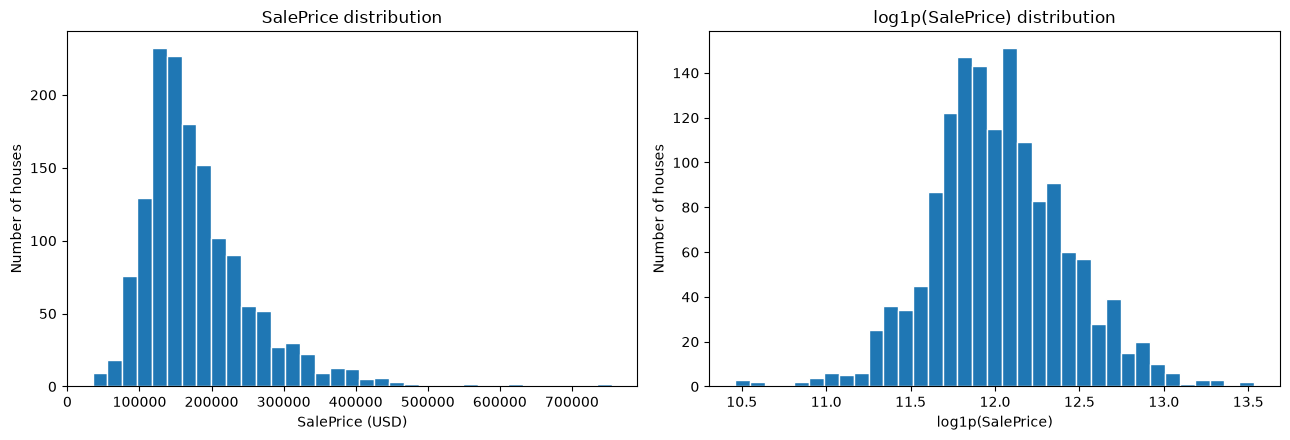

,SalePrice_USD
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
1%,61815.970000
5%,88000.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
95%,326100.000000


In [4]:
sale_prices = df[TARGET].dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sale_prices, bins=35, edgecolor="white")
axes[0].set_title("SalePrice distribution")
axes[0].set_xlabel("SalePrice (USD)")
axes[0].set_ylabel("Number of houses")
axes[1].hist(np.log1p(sale_prices), bins=35, edgecolor="white")
axes[1].set_title("log1p(SalePrice) distribution")
axes[1].set_xlabel("log1p(SalePrice)")
axes[1].set_ylabel("Number of houses")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_saleprice_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

display(sale_prices.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("SalePrice_USD"))


## 3. Missingness

Many Ames columns encode absence structurally (for example, no pool or no garage). A missing value is therefore not always an accidental data-entry failure. We will inspect missingness and decide how to represent it in the model pipeline; this notebook does not automatically drop columns or rows.


,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


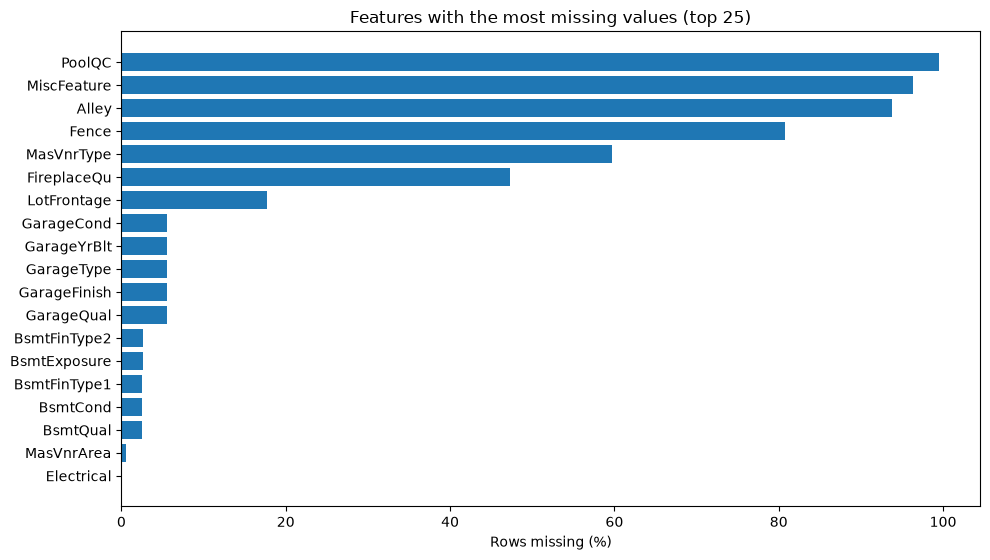

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing) == 0:
    print("No missing values found.")
else:
    missing_summary = pd.DataFrame({
        "missing_count": missing,
        "missing_percent": (missing / len(df) * 100).round(2),
    })
    display(missing_summary)
    top = missing_summary.head(25).sort_values("missing_percent")
    fig, ax = plt.subplots(figsize=(10, max(4, 0.30 * len(top))))
    ax.barh(top.index.astype(str), top["missing_percent"])
    ax.set_xlabel("Rows missing (%)")
    ax.set_title("Features with the most missing values (top 25)")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "02_missingness_top25.png", dpi=160, bbox_inches="tight")
    plt.show()


## 4. Numeric features associated with SalePrice

These are exploratory associations, not evidence of causation. The numeric correlation analysis includes the target but excludes identifier columns such as `Id` from the ranked predictor list.


,correlation_with_SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


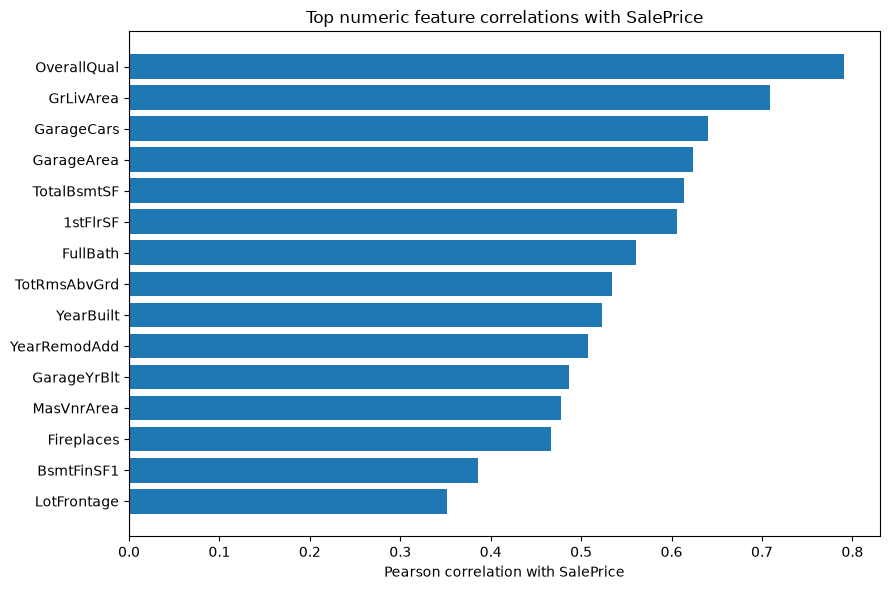

In [6]:
numeric = df.select_dtypes(include=[np.number])
if TARGET not in numeric.columns:
    raise ValueError("SalePrice must be numeric for this analysis.")
correlations = numeric.corr(numeric_only=True)[TARGET].drop(labels=[TARGET], errors="ignore")
correlations = correlations.drop(labels=["Id"], errors="ignore").dropna()
correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
display(correlations.head(20).rename("correlation_with_SalePrice").to_frame())

top_corr = correlations.head(15).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_corr.index.astype(str), top_corr.values)
ax.axvline(0, linewidth=0.8)
ax.set_xlabel("Pearson correlation with SalePrice")
ax.set_title("Top numeric feature correlations with SalePrice")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_numeric_correlations.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Inspect selected relationships

`GrLivArea`, `OverallQual`, and `TotalBsmtSF` are used here when present. The plots help identify broad relationships and potentially influential observations. Outliers must be checked against data definitions before any exclusion.


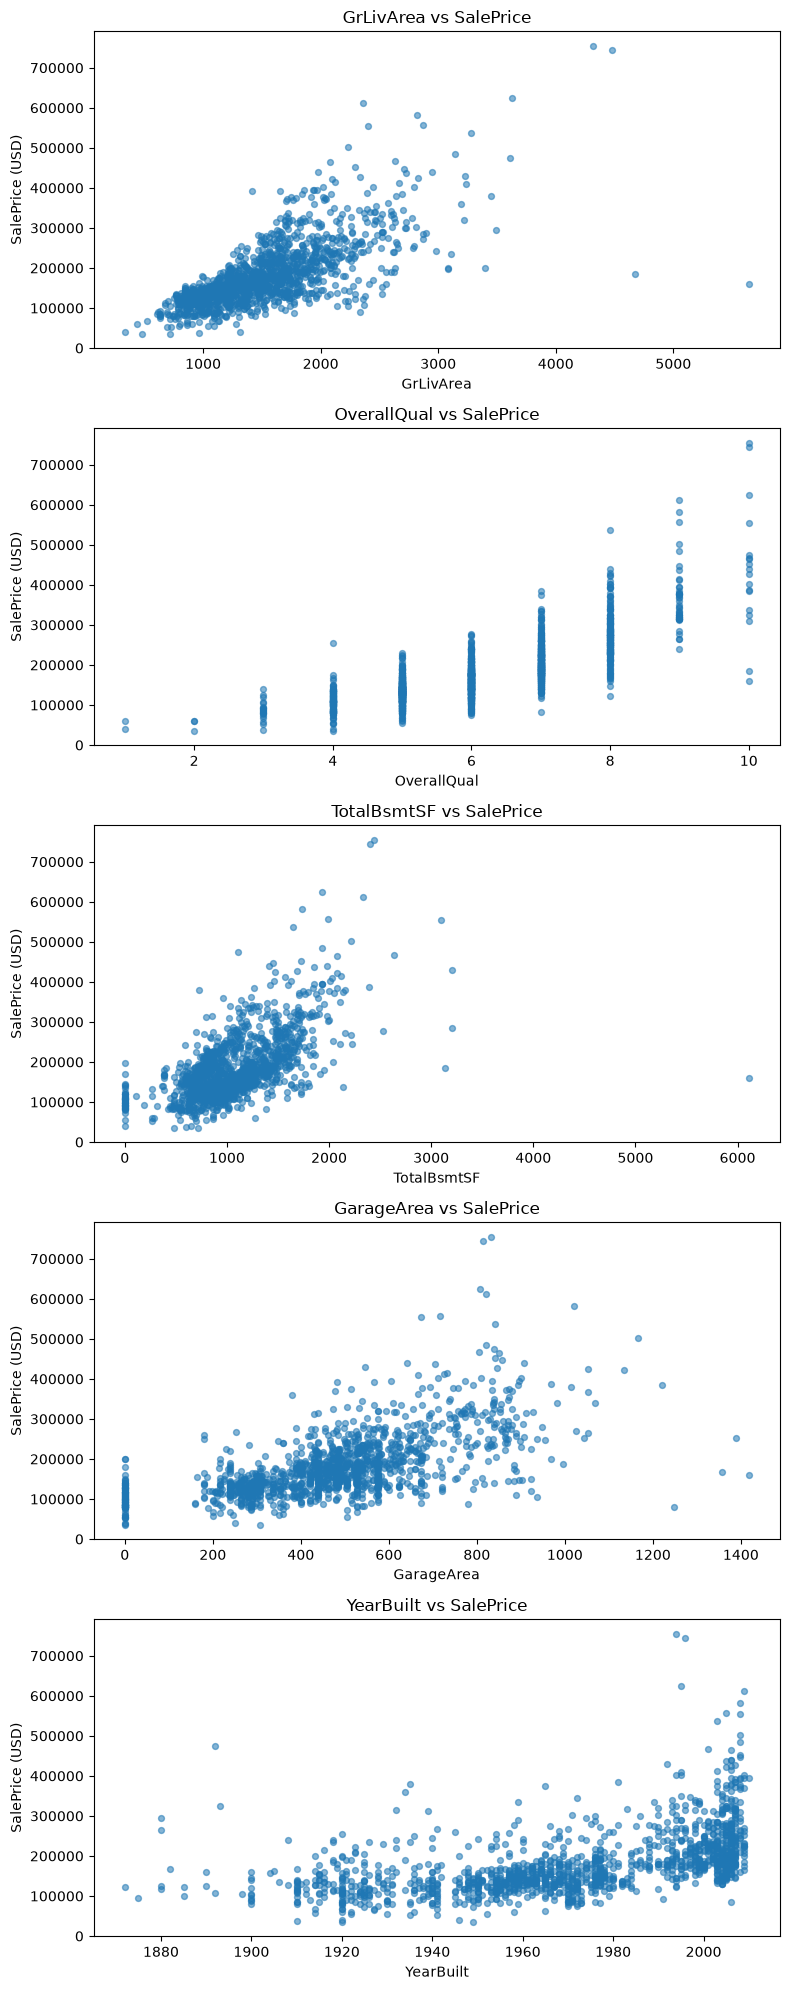

In [7]:
candidate_features = ["GrLivArea", "OverallQual", "TotalBsmtSF", "GarageArea", "YearBuilt"]
features = [c for c in candidate_features if c in df.columns]
if not features:
    print("None of the configured relationship features are present in this dataset.")
else:
    n = len(features)
    fig, axes = plt.subplots(n, 1, figsize=(8, 4 * n), squeeze=False)
    for ax, feature in zip(axes[:, 0], features):
        x = pd.to_numeric(df[feature], errors="coerce")
        y = pd.to_numeric(df[TARGET], errors="coerce")
        valid = x.notna() & y.notna()
        ax.scatter(x[valid], y[valid], alpha=0.55, s=18)
        ax.set_xlabel(feature)
        ax.set_ylabel("SalePrice (USD)")
        ax.set_title(f"{feature} vs SalePrice")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "04_selected_feature_relationships.png", dpi=160, bbox_inches="tight")
    plt.show()


## 6. Neighborhood price patterns

Neighborhood summaries are descriptive. Categories with few observations can have unstable medians, so the table includes their sample counts.


,count,median,mean
Neighborhood,,,
NridgHt,77,315000.0,316270.623377
NoRidge,41,301500.0,335295.317073
StoneBr,25,278000.0,310499.000000
Timber,38,228475.0,242247.447368
Somerst,86,225500.0,225379.837209
Veenker,11,218000.0,238772.727273
Crawfor,51,200624.0,210624.725490
ClearCr,28,200250.0,212565.428571
CollgCr,150,197200.0,197965.773333


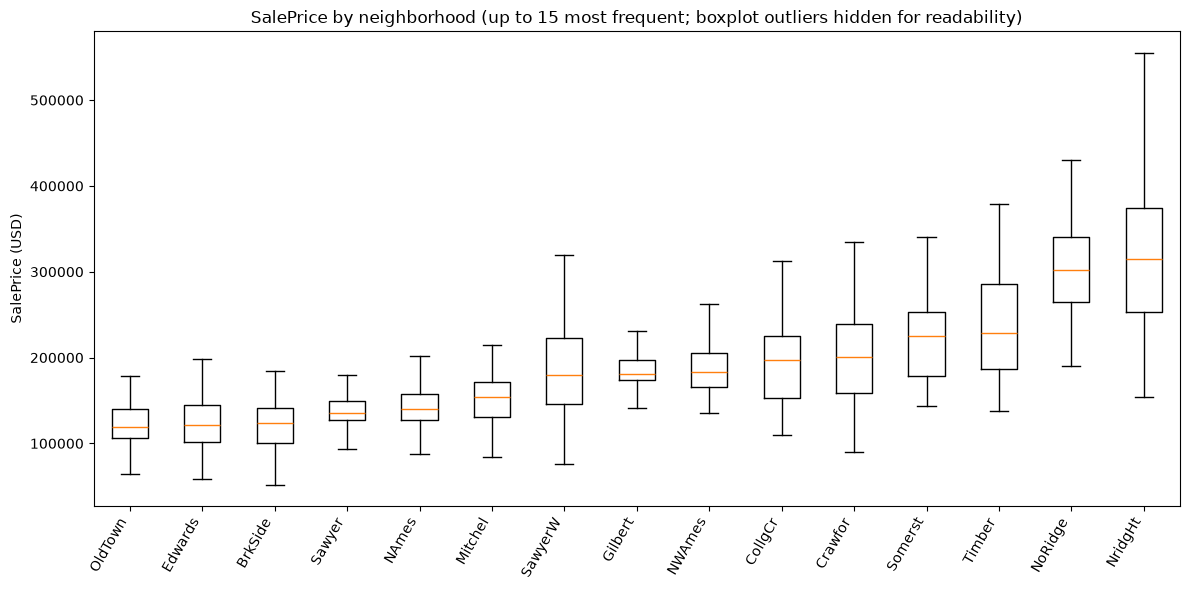

In [8]:
if "Neighborhood" in df.columns:
    neighborhood_summary = (
        df.dropna(subset=["Neighborhood", TARGET])
          .groupby("Neighborhood")[TARGET]
          .agg(["count", "median", "mean"])
          .sort_values("median", ascending=False)
    )
    display(neighborhood_summary)

    counts = df["Neighborhood"].value_counts()
    selected = counts.head(15).index
    plot_df = df[df["Neighborhood"].isin(selected)].dropna(subset=["Neighborhood", TARGET])
    order = (plot_df.groupby("Neighborhood")[TARGET].median().sort_values().index.tolist())
    values = [plot_df.loc[plot_df["Neighborhood"] == name, TARGET].to_numpy() for name in order]
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.boxplot(values, tick_labels=order, showfliers=False)
    ax.set_xticklabels(order, rotation=60, ha="right")
    ax.set_ylabel("SalePrice (USD)")
    ax.set_title("SalePrice by neighborhood (up to 15 most frequent; boxplot outliers hidden for readability)")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "05_saleprice_by_neighborhood.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Neighborhood column not found; skipping neighborhood analysis.")


## 7. Potential influential observations (flag only)

A commonly inspected relationship in Ames data is above-ground living area versus sale price. The following table flags very large `GrLivArea` values for inspection only. It does not remove records or claim that they are errors.


In [9]:
if "GrLivArea" in df.columns:
    area = pd.to_numeric(df["GrLivArea"], errors="coerce")
    threshold = area.quantile(0.99)
    cols = [c for c in ["Id", "GrLivArea", "OverallQual", TARGET] if c in df.columns]
    flagged = df.loc[area >= threshold, cols].sort_values("GrLivArea", ascending=False)
    print(f"99th-percentile GrLivArea threshold: {threshold:g}")
    display(flagged)
else:
    print("GrLivArea column not present; no area-based flagging performed.")


99th-percentile GrLivArea threshold: 3123.48


,Id,GrLivArea,OverallQual,SalePrice
1298,1299,5642,10,160000
523,524,4676,10,184750
1182,1183,4476,10,745000
691,692,4316,10,755000
1169,1170,3627,10,625000
185,186,3608,10,475000
304,305,3493,7,295000
1268,1269,3447,8,381000
635,636,3395,6,200000
769,770,3279,8,538000


## 8. EDA handoff notes

Before modelling, the team should record: (1) any identified data-quality issues, (2) how missingness will be represented, (3) whether flagged observations are valid, (4) features available to the app user, and (5) the validation strategy. Do not use the holdout set to make model or preprocessing choices.

Figures generated by this notebook are saved in `reports/figures/ames_eda/`. Review them before committing; commit only the figures that support the final report. The notebook does not train a model or modify the input CSV.
